In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

In [87]:
from google.colab import files

uploaded = files.upload()

Saving student budget - Form responses 1 (2).csv to student budget - Form responses 1 (2) (1).csv


In [88]:
student_budget = list(uploaded.keys())[0]

df_raw = pd.read_csv(student_budget)

df = df_raw.copy()

df.head()

,Timestamp,name,Age(In numbers),Current Grade/college year,Which currency are you using for the amounts in this form?,How much pocket money do you get monthly/allowance? ( Enter 0 if you don't receive it),"If you have a job, part-time work or freelance, how much do you earn from it each month? ( Enter 0 if you don't earn from work.)","Approximately how much additional money do you receive/earn from other sources in a typical month?\nExamples: gifts, competitions, occasional work, etc. (Enter 0 if none.)","What are your main sources of this additional money?\nExample: gifts, freelance work, competitions, etc.\n(Skip this if it doesn't apply to you)",Approximately how much do you spend on RENT / ACCOMMODATION each month?\n(Enter 0 if you don't have to pay rent. ),...,Approximately how much do you spend on SCHOOL / COLLEGE supplies or activities each month? (Enter 0 if you don't),Approximately how much do you spend on PHONE / INTERNET each month?\n(enter 0 if you don't),"Do you have any other fixed spendings? \nif yes, Answer in points with the amount and on what",Approximately how much do you spend on FOOD / EATING OUT each month?,Approximately how much do you spend on HANGING OUT / SOCIAL ACTIVITIES each month?,Approximately how much do you spend on SHOPPING / PERSONAL PURCHASES each month?,Approximately how much do you spend on ENTERTAINMENT / SUBSCRIPTIONS / HOBBIES each month?,"Any other thing on which you splurge on? \nif yes, answer in points with amount and for what",Approximately how much money do you currently save each month? (Enter 0 if you don't end up saving),"Do you currently have a savings goal? If yes, what are you saving for and approximately how much do you need?\nExample: Laptop – ₹50,000 / Trip – ₹20,000 / Emergency fund – ₹10,000. Write N/A if you don't have a specific goal."
0,01/09/2026 13:54:10,Mysha Saud,16,Grade 11,INR (₹),1000,0,500,gifts,0,...,500,0,nopee,2000,1500,500,2500,-Mostly snacks or drinks like redbull \n- usel...,500-700,NaN
1,01/09/2026 14:27:52,Navadeep,20,College 4th year,INR (₹),5000,10k,5 to 6k,Freelance work,0,...,2000,500,Sip-500,2000,0,2500,0,0,1000,Yeah for a laptop 1lakh
2,01/09/2026 14:30:50,Syaan polley,19,College 1st year,INR (₹),5000,6-8k,1-2k,Gift from relatives,Rent and food 8k and pocket money 5k,...,100-1500,400,Gym 750 bahar ka khana 2-3k cigrate 2-3k,2-3k,1/2,3-4k,0,NaN,500-1000,Laptop
3,01/09/2026 15:24:08,Payal,22,College 4th year,INR (₹),0,5-10k,2000,Freelance,0,...,2000,500,No,1000,0,2000,0,NaN,2000,Trading - 20000
4,01/09/2026 16:14:06,Vaibhavi Kore,17,Grade 12,INR (₹),0,0,500,NaN,0,...,0,0,NaN,500,500,2000,0,NaN,0,NaN


In [89]:
print("Dataset Shape:")
print(df.shape)

Dataset Shape:
(52, 22)


In [90]:
print("Column Names:")

for column in df.columns:
    print(column)

Column Names:
Timestamp
name
Age(In numbers)
Current Grade/college year
Which currency are you using for the amounts in this form?  
How much pocket money do you get monthly/allowance? ( Enter 0 if you don't receive it)
If you have a job, part-time work or freelance, how much do you earn from it each month?  ( Enter 0 if you don't earn from work.)
Approximately how much additional money do you receive/earn from other sources in a typical month?
Examples: gifts, competitions, occasional work, etc. (Enter 0 if none.)
What are your main sources of this additional money?
Example: gifts, freelance work, competitions, etc.
(Skip this if it doesn't apply to you)
  Approximately how much do you spend on RENT / ACCOMMODATION each month?
(Enter 0 if you don't have to pay rent. ) 
 Approximately how much do you spend on TRANSPORT each month?
(Enter 0 if you don't. ) 
  Approximately how much do you spend on GROCERIES / HOUSEHOLD ITEMS each month?   (Enter 0 if you don't. )
  Approximately how muc

In [91]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 22 columns):
 #   Column                                                                                                                                                                                                                             Non-Null Count  Dtype 
---  ------                                                                                                                                                                                                                             --------------  ----- 
 0   Timestamp                                                                                                                                                                                                                          52 non-null     object
 1   name                                                                                                                           

In [92]:
print("Missing Values in Each Column:")

print(df.isnull().sum())

Missing Values in Each Column:
Timestamp                                                                                                                                                                                                                              0
name                                                                                                                                                                                                                                   0
Age(In numbers)                                                                                                                                                                                                                        0
Current Grade/college year                                                                                                                                                                                                             0
Which currency are you using for the 

In [93]:
df.columns = [
    "timestamp",
    "name",
    "age",
    "education_stage",
    "currency",

    "pocket_money",
    "work_income",
    "additional_income",
    "additional_income_source",

    "rent",
    "transport",
    "groceries",
    "education_expenses",
    "phone_internet",
    "other_fixed_expenses",

    "food_eating_out",
    "social_activities",
    "shopping",
    "entertainment_hobbies",
    "other_splurging",

    "monthly_savings",
    "savings_goal"
]

print(df.columns.tolist())

['timestamp', 'name', 'age', 'education_stage', 'currency', 'pocket_money', 'work_income', 'additional_income', 'additional_income_source', 'rent', 'transport', 'groceries', 'education_expenses', 'phone_internet', 'other_fixed_expenses', 'food_eating_out', 'social_activities', 'shopping', 'entertainment_hobbies', 'other_splurging', 'monthly_savings', 'savings_goal']


In [94]:
financial_columns = [
    "pocket_money",
    "work_income",
    "additional_income",
    "rent",
    "transport",
    "groceries",
    "education_expenses",
    "phone_internet",
    "food_eating_out",
    "social_activities",
    "shopping",
    "entertainment_hobbies",
    "monthly_savings"
]

for column in financial_columns:
    print("\n" + "=" * 50)
    print(column.upper())
    print("=" * 50)
    print(df[column].unique())


POCKET_MONEY
['1000' '5000' '0' '2000' '10000' '3000' '1500' '700' '4000' '500' '₹500'
 '800' '30000' '2500' '6000' '25000' '1lakh' '10,000' '7500' '45000']

WORK_INCOME
['0' '10k' '6-8k' '5-10k' '₹0.00' '45000' '30000' 'O' 'no' '20000' '12000'
 '18000' '8000' '5000' '35000' '1000' '3000' '15,000' 'o' '10000' '55000'
 '12500' '15000' 'NONE']

ADDITIONAL_INCOME
['500' '5 to 6k' '1-2k' '2000' '₹0.00' '0' '5000' '3000' 'O' '1000'
 '2k-3k' '200' '1000-2000' '2000-5000' '1000-3000' nan '₹500-₹1000' '1500'
 '₹5,000/month' '2000-3000' '25000']

RENT
['0' 'Rent and food 8k and pocket money 5k ' '10000' 'O' 'no' '7000'
 '8000' '5000' '₹0' '6000' '15000' '30000']

TRANSPORT
['0' '500-600' '1000' '2000' '1200' '1500' '500' '2k' '150' '500-1000'
 '2000-2500' '300' '1800' '800' '200' '₹5,000 ' '700' '2500' '4000' '3500']

GROCERIES
['0' '3000' '1000-1500' '500' '6000' '5000' 'O' '4k' '200' '1500' '4500'
 '1000' '3500' '4000' '2500' '₹10,000+' '8000']

EDUCATION_EXPENSES
['500' '2000' '100-1500' '0

In [95]:
def clean_money(value):


    if pd.isna(value):
        return np.nan

    value = str(value).lower().strip()

    if value in ["0", "₹0.00", "no", "none", "o"]:
        return 0.0

    if value in ["idk", "don't know", "dont know", "n/a", "na", ""]:
        return np.nan

    value = value.replace("₹", "").replace(",", "")


    value = value.replace(" to ", "-")

    if "upto" in value:
        numbers = re.findall(r"\d+(?:\.\d+)?", value)

        if len(numbers) > 0:
            return float(numbers[0]) / 2

        return np.nan


    numbers = re.findall(r"\d+(?:\.\d+)?", value)


    if len(numbers) == 0:
        return np.nan

    numbers = [float(number) for number in numbers]

    if "k" in value:
        numbers = [number * 1000 for number in numbers]

    if len(numbers) >= 2:
        return (numbers[0] + numbers[1]) / 2


    return numbers[0]

In [96]:
test_values = [
    "1000",
    "₹1000",
    "10k",
    "6-8k",
    "5-10k",
    "500-600",
    "5 to 6k",
    "2k-3k",
    "Upto 500",
    "Idk",
    "no",
    "O"
]

for value in test_values:
    print(f"{value} → {clean_money(value)}")

1000 → 1000.0
₹1000 → 1000.0
10k → 10000.0
6-8k → 7000.0
5-10k → 7500.0
500-600 → 550.0
5 to 6k → 5500.0
2k-3k → 2500.0
Upto 500 → 250.0
Idk → nan
no → 0.0
O → 0.0


In [97]:
money_columns = [
    "pocket_money",
    "work_income",
    "additional_income",
    "transport",
    "groceries",
    "education_expenses",
    "phone_internet",
    "food_eating_out",
    "shopping",
    "entertainment_hobbies",
    "monthly_savings"
]

for column in money_columns:
    df[column] = df[column].apply(clean_money)

print("Financial columns cleaned successfully!")

Financial columns cleaned successfully!


In [98]:
df[money_columns].head(10)

,pocket_money,work_income,additional_income,transport,groceries,education_expenses,phone_internet,food_eating_out,shopping,entertainment_hobbies,monthly_savings
0,1000.0,0.0,500.0,0.0,0.0,500.0,0.0,2000.0,500.0,2500.0,600.0
1,5000.0,10000.0,5500.0,0.0,3000.0,2000.0,500.0,2000.0,2500.0,0.0,1000.0
2,5000.0,7000.0,1500.0,550.0,1250.0,800.0,400.0,2500.0,3500.0,0.0,750.0
3,0.0,7500.0,2000.0,1000.0,500.0,2000.0,500.0,1000.0,2000.0,0.0,2000.0
4,0.0,0.0,500.0,0.0,0.0,0.0,0.0,500.0,2000.0,0.0,0.0
5,1000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1000.0
6,2000.0,45000.0,0.0,2000.0,0.0,10000.0,1000.0,700.0,4000.0,0.0,NaN
7,0.0,30000.0,5000.0,0.0,6000.0,0.0,1000.0,5000.0,3000.0,0.0,20000.0
8,10000.0,0.0,3000.0,1000.0,5000.0,0.0,2000.0,5000.0,4000.0,500.0,750.0
9,0.0,0.0,500.0,1200.0,0.0,300.0,0.0,3000.0,3000.0,1000.0,0.0


In [99]:
df[money_columns].head(10)

,pocket_money,work_income,additional_income,transport,groceries,education_expenses,phone_internet,food_eating_out,shopping,entertainment_hobbies,monthly_savings
0,1000.0,0.0,500.0,0.0,0.0,500.0,0.0,2000.0,500.0,2500.0,600.0
1,5000.0,10000.0,5500.0,0.0,3000.0,2000.0,500.0,2000.0,2500.0,0.0,1000.0
2,5000.0,7000.0,1500.0,550.0,1250.0,800.0,400.0,2500.0,3500.0,0.0,750.0
3,0.0,7500.0,2000.0,1000.0,500.0,2000.0,500.0,1000.0,2000.0,0.0,2000.0
4,0.0,0.0,500.0,0.0,0.0,0.0,0.0,500.0,2000.0,0.0,0.0
5,1000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1000.0
6,2000.0,45000.0,0.0,2000.0,0.0,10000.0,1000.0,700.0,4000.0,0.0,NaN
7,0.0,30000.0,5000.0,0.0,6000.0,0.0,1000.0,5000.0,3000.0,0.0,20000.0
8,10000.0,0.0,3000.0,1000.0,5000.0,0.0,2000.0,5000.0,4000.0,500.0,750.0
9,0.0,0.0,500.0,1200.0,0.0,300.0,0.0,3000.0,3000.0,1000.0,0.0


In [100]:
df["rent"] = df["rent"].apply(clean_money)
df["social_activities"] = df["social_activities"].apply(clean_money)

print("Rent and social activities cleaned!")

Rent and social activities cleaned!


In [101]:
print(df.isnull().sum())

timestamp                    0
name                         0
age                          0
education_stage              0
currency                     0
pocket_money                 0
work_income                  0
additional_income            1
additional_income_source    27
rent                         0
transport                    0
groceries                    0
education_expenses           0
phone_internet               0
other_fixed_expenses        15
food_eating_out              0
social_activities            0
shopping                     0
entertainment_hobbies        0
other_splurging             19
monthly_savings              2
savings_goal                27
dtype: int64


In [102]:
financial_columns = [
    "pocket_money",
    "work_income",
    "additional_income",
    "rent",
    "transport",
    "groceries",
    "education_expenses",
    "phone_internet",
    "food_eating_out",
    "social_activities",
    "shopping",
    "entertainment_hobbies",
    "monthly_savings"
]

problem_rows = df[
    df[financial_columns].isnull().any(axis=1)
]

problem_rows

,timestamp,name,age,education_stage,currency,pocket_money,work_income,additional_income,additional_income_source,rent,...,education_expenses,phone_internet,other_fixed_expenses,food_eating_out,social_activities,shopping,entertainment_hobbies,other_splurging,monthly_savings,savings_goal
6,01/09/2026 17:27:33,Lavender,18,College 1st year,INR (₹),2000.0,45000.0,0.0,NaN,0.0,...,10000.0,1000.0,No,700.0,0.0,4000.0,0.0,No,NaN,Na
23,07/09/2026 22:49:25,Kanika,17,Grade 12,INR (₹),500.0,0.0,NaN,500,0.0,...,0.0,0.0,0,200.0,0.0,150.0,0.0,200,500.0,NaN
51,09/09/2026 16:40:46,VANYA CHANDWANI,16,Grade 11,INR (₹),2500.0,0.0,25000.0,NaN,0.0,...,600.0,0.0,NOT EXACTLY,1100.0,700.0,600.0,0.0,NONE \n,NaN,HONESTLY YES I DO SAVE ALL GIFT MONEY I GET FR...


In [103]:
df.loc[6, financial_columns]

,6
pocket_money,2000.0
work_income,45000.0
additional_income,0.0
rent,0.0
transport,2000.0
groceries,0.0
education_expenses,10000.0
phone_internet,1000.0
food_eating_out,700.0
social_activities,0.0


In [104]:
df_raw.loc[6]

,6
Timestamp,01/09/2026 17:27:33
name,Lavender
Age(In numbers),18
Current Grade/college year,College 1st year
Which currency are you using for the amounts in this form?,INR (₹)
How much pocket money do you get monthly/allowance? ( Enter 0 if you don't receive it),2000
"If you have a job, part-time work or freelance, how much do you earn from it each month? ( Enter 0 if you don't earn from work.)",45000
"Approximately how much additional money do you receive/earn from other sources in a typical month?\nExamples: gifts, competitions, occasional work, etc. (Enter 0 if none.)",0
"What are your main sources of this additional money?\nExample: gifts, freelance work, competitions, etc.\n(Skip this if it doesn't apply to you)",NaN
Approximately how much do you spend on RENT / ACCOMMODATION each month?\n(Enter 0 if you don't have to pay rent. ),0


In [105]:
df.columns

Index(['timestamp', 'name', 'age', 'education_stage', 'currency',
       'pocket_money', 'work_income', 'additional_income',
       'additional_income_source', 'rent', 'transport', 'groceries',
       'education_expenses', 'phone_internet', 'other_fixed_expenses',
       'food_eating_out', 'social_activities', 'shopping',
       'entertainment_hobbies', 'other_splurging', 'monthly_savings',
       'savings_goal'],
      dtype='object')

In [106]:
df.isnull().sum()

,0
timestamp,0
name,0
age,0
education_stage,0
currency,0
pocket_money,0
work_income,0
additional_income,1
additional_income_source,27
rent,0


In [107]:
df["additional_income_source"] = df["additional_income_source"].fillna("None")

df["other_fixed_expenses"] = df["other_fixed_expenses"].fillna("None")

df["other_splurging"] = df["other_splurging"].fillna("None")

df["savings_goal"] = df["savings_goal"].fillna("No savings goal specified")

In [108]:
df.isnull().sum()

,0
timestamp,0
name,0
age,0
education_stage,0
currency,0
pocket_money,0
work_income,0
additional_income,1
additional_income_source,0
rent,0


In [109]:
print("OTHER FIXED EXPENSES:")
print(df["other_fixed_expenses"].dropna().unique())

print("\nOTHER SPLURGING:")
print(df["other_splurging"].dropna().unique())

OTHER FIXED EXPENSES:
['nopee' 'Sip-500' 'Gym 750 bahar ka khana 2-3k cigrate 2-3k' 'No' 'None'
 'Yes, around 10k' '0' 'SIP- 1000' 'gym - 800' '1200- gym' 'gym 1000'
 '1500' '700' 'sip 2000' '800' '₹1,000' '1500-medical' 'Noo' '2500'
 'creatine protein 3000' 'NOT EXACTLY']

OTHER SPLURGING:
['-Mostly snacks or drinks like redbull \n- useless stationary ' '0'
 'None' 'No' 'Cant recollect ' 'No ' '200' '100' '700' '44580' '500'
 'FOOTBALL SHOES 15000' 'NONE \n']


In [110]:
import numpy as np

df["other_fixed_expenses_amount"] = 0.0
df["other_splurging_amount"] = 0.0

# Specific fixed expense responses
df.loc[df["other_fixed_expenses"].str.lower().isin(["no", "nopee", "none"]),
       "other_fixed_expenses_amount"] = 0

df.loc[df["other_fixed_expenses"].str.lower() == "sip-500",
       "other_fixed_expenses_amount"] = 500

df.loc[df["other_fixed_expenses"].str.lower() == "yes, around 10k",
       "other_fixed_expenses_amount"] = 10000

print("New expense amount columns created!")

New expense amount columns created!


In [111]:
df[[
    "other_fixed_expenses",
    "other_fixed_expenses_amount",
    "other_splurging",
    "other_splurging_amount"
]]

df.loc[
    df["other_fixed_expenses"] == "Gym 750 bahar ka khana 2-3k cigrate 2-3k",
    "other_fixed_expenses_amount"
] = 3250

In [112]:
df[["other_fixed_expenses", "other_fixed_expenses_amount"]]

,other_fixed_expenses,other_fixed_expenses_amount
0,nopee,0.0
1,Sip-500,500.0
2,Gym 750 bahar ka khana 2-3k cigrate 2-3k,3250.0
3,No,0.0
4,None,0.0
5,No,0.0
6,No,0.0
7,"Yes, around 10k",10000.0
8,None,0.0
9,None,0.0


In [113]:
df[[
    "other_fixed_expenses",
    "other_fixed_expenses_amount",
    "other_splurging",
    "other_splurging_amount"
]]

,other_fixed_expenses,other_fixed_expenses_amount,other_splurging,other_splurging_amount
0,nopee,0.0,-Mostly snacks or drinks like redbull \n- usel...,0.0
1,Sip-500,500.0,0,0.0
2,Gym 750 bahar ka khana 2-3k cigrate 2-3k,3250.0,None,0.0
3,No,0.0,None,0.0
4,None,0.0,None,0.0
5,No,0.0,0,0.0
6,No,0.0,No,0.0
7,"Yes, around 10k",10000.0,No,0.0
8,None,0.0,No,0.0
9,None,0.0,None,0.0


In [114]:
def extract_amount(value):

    if pd.isna(value):
        return 0

    value = str(value).lower().strip()

    # Responses that mean no expense
    no_values = [
        "no", "none", "nope", "nopee", "noo",
        "0", "not exactly", "cant recollect"
    ]

    if value in no_values:
        return 0

    # Remove commas and currency symbol
    value = value.replace(",", "")
    value = value.replace("₹", "")

    # Find numbers
    numbers = re.findall(r'\d+(?:\.\d+)?', value)

    if not numbers:
        return 0

    # Convert found numbers to float
    numbers = [float(num) for num in numbers]

    # Add them if multiple amounts are mentioned
    return sum(numbers)

In [115]:
df["other_fixed_expenses_amount"] = df["other_fixed_expenses"].apply(extract_amount)

df["other_splurging_amount"] = df["other_splurging"].apply(extract_amount)

In [116]:
df[[
    "other_fixed_expenses",
    "other_fixed_expenses_amount",
    "other_splurging",
    "other_splurging_amount"
]]

,other_fixed_expenses,other_fixed_expenses_amount,other_splurging,other_splurging_amount
0,nopee,0.0,-Mostly snacks or drinks like redbull \n- usel...,0.0
1,Sip-500,500.0,0,0.0
2,Gym 750 bahar ka khana 2-3k cigrate 2-3k,760.0,None,0.0
3,No,0.0,None,0.0
4,None,0.0,None,0.0
5,No,0.0,0,0.0
6,No,0.0,No,0.0
7,"Yes, around 10k",10.0,No,0.0
8,None,0.0,No,0.0
9,None,0.0,None,0.0


In [117]:
df.loc[
    df["other_fixed_expenses"] == "Gym 750 bahar ka khana 2-3k cigrate 2-3k",
    "other_fixed_expenses_amount"
] = 2500

In [118]:
df[[
    "other_fixed_expenses",
    "other_fixed_expenses_amount"
]]

,other_fixed_expenses,other_fixed_expenses_amount
0,nopee,0.0
1,Sip-500,500.0
2,Gym 750 bahar ka khana 2-3k cigrate 2-3k,2500.0
3,No,0.0
4,None,0.0
5,No,0.0
6,No,0.0
7,"Yes, around 10k",10.0
8,None,0.0
9,None,0.0


In [119]:
df.loc[
    df["other_fixed_expenses"] == "Yes, around 10k",
    "other_fixed_expenses_amount"
] = 10000
df[df["other_fixed_expenses"] == "Yes, around 10k"][
    ["other_fixed_expenses", "other_fixed_expenses_amount"]
]

,other_fixed_expenses,other_fixed_expenses_amount
7,"Yes, around 10k",10000.0


In [120]:
financial_columns = [
    'pocket_money',
    'work_income',
    'additional_income',
    'rent',
    'transport',
    'groceries',
    'education_expenses',
    'phone_internet',
    'other_fixed_expenses_amount',
    'food_eating_out',
    'social_activities',
    'shopping',
    'entertainment_hobbies',
    'other_splurging_amount',
    'monthly_savings'
]

df[financial_columns]

,pocket_money,work_income,additional_income,rent,transport,groceries,education_expenses,phone_internet,other_fixed_expenses_amount,food_eating_out,social_activities,shopping,entertainment_hobbies,other_splurging_amount,monthly_savings
0,1000.0,0.0,500.0,0.0,0.0,0.0,500.0,0.0,0.0,2000.0,1500.0,500.0,2500.0,0.0,600.0
1,5000.0,10000.0,5500.0,0.0,0.0,3000.0,2000.0,500.0,500.0,2000.0,0.0,2500.0,0.0,0.0,1000.0
2,5000.0,7000.0,1500.0,6500.0,550.0,1250.0,800.0,400.0,2500.0,2500.0,1.5,3500.0,0.0,0.0,750.0
3,0.0,7500.0,2000.0,0.0,1000.0,500.0,2000.0,500.0,0.0,1000.0,0.0,2000.0,0.0,0.0,2000.0
4,0.0,0.0,500.0,0.0,0.0,0.0,0.0,0.0,0.0,500.0,500.0,2000.0,0.0,0.0,0.0
5,1000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1000.0
6,2000.0,45000.0,0.0,0.0,2000.0,0.0,10000.0,1000.0,0.0,700.0,0.0,4000.0,0.0,0.0,NaN
7,0.0,30000.0,5000.0,0.0,0.0,6000.0,0.0,1000.0,10000.0,5000.0,2000.0,3000.0,0.0,0.0,20000.0
8,10000.0,0.0,3000.0,10000.0,1000.0,5000.0,0.0,2000.0,0.0,5000.0,3000.0,4000.0,500.0,0.0,750.0
9,0.0,0.0,500.0,0.0,1200.0,0.0,300.0,0.0,0.0,3000.0,1000.0,3000.0,1000.0,0.0,0.0


In [121]:
df[financial_columns].dtypes

,0
pocket_money,float64
work_income,float64
additional_income,float64
rent,float64
transport,float64
groceries,float64
education_expenses,float64
phone_internet,float64
other_fixed_expenses_amount,float64
food_eating_out,float64


In [122]:
df[financial_columns].isnull().sum()

,0
pocket_money,0
work_income,0
additional_income,1
rent,0
transport,0
groceries,0
education_expenses,0
phone_internet,0
other_fixed_expenses_amount,0
food_eating_out,0


In [123]:
df[df["additional_income"].isnull()][
    ["name", "additional_income", "additional_income_source"]
]


,name,additional_income,additional_income_source
23,Kanika,NaN,500


In [124]:
df[df["monthly_savings"].isnull()][
    ["name", "monthly_savings", "pocket_money", "work_income"]
]

,name,monthly_savings,pocket_money,work_income
6,Lavender,NaN,2000.0,45000.0
51,VANYA CHANDWANI,NaN,2500.0,0.0


In [125]:
df.loc[df["name"] == "Kanika", "additional_income"] = 500

In [126]:
df.loc[df["name"] == "Kanika", "additional_income_source"] = "Not specified"

In [127]:
df[financial_columns].isnull().sum()

,0
pocket_money,0
work_income,0
additional_income,0
rent,0
transport,0
groceries,0
education_expenses,0
phone_internet,0
other_fixed_expenses_amount,0
food_eating_out,0


In [128]:
df[financial_columns].describe()

,pocket_money,work_income,additional_income,rent,transport,groceries,education_expenses,phone_internet,other_fixed_expenses_amount,food_eating_out,social_activities,shopping,entertainment_hobbies,other_splurging_amount,monthly_savings
count,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,50.000000
mean,4307.692308,6788.461538,1699.038462,1875.000000,1190.384615,1378.846154,1265.384615,410.576923,625.000000,1809.615385,1167.336538,2563.461538,611.711538,1174.615385,2304.000000
std,7927.931416,11996.055787,3603.028279,5161.010503,1073.798392,2287.226811,1655.843440,511.374210,1530.074329,1496.172845,1021.301778,6843.761403,1119.556711,6479.864578,3730.949433
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,500.000000,0.000000,150.000000,0.000000,500.000000,0.000000,137.500000,0.000000,0.000000,500.000000,200.000000,575.000000,0.000000,0.000000,275.000000
50%,2000.000000,0.000000,500.000000,0.000000,1000.000000,0.000000,700.000000,400.000000,0.000000,1650.000000,1000.000000,1500.000000,300.000000,0.000000,750.000000
75%,5000.000000,10000.000000,2000.000000,0.000000,1500.000000,1750.000000,2000.000000,625.000000,850.000000,2500.000000,2000.000000,2500.000000,550.000000,0.000000,2875.000000
max,45000.000000,55000.000000,25000.000000,30000.000000,5000.000000,10000.000000,10000.000000,2500.000000,10000.000000,6000.000000,4000.000000,50000.000000,6860.000000,44580.000000,20000.000000


In [129]:
df[df["shopping"] >= 10000][
    ["name", "age", "education_stage", "shopping"]
]

,name,age,education_stage,shopping
40,pakkshal,18,College 2nd year,50000.0


In [130]:
df[df["other_splurging_amount"] >= 10000][
    ["name", "age", "education_stage", "other_splurging", "other_splurging_amount"]
]

,name,age,education_stage,other_splurging,other_splurging_amount
40,pakkshal,18,College 2nd year,44580,44580.0
50,Arjav Jain,18,College 1st year,FOOTBALL SHOES 15000,15000.0


In [131]:
df[
    (df["additional_income"] >= 10000) |
    (df["shopping"] >= 10000) |
    (df["other_splurging_amount"] >= 10000) |
    (df["work_income"] >= 30000) |
    (df["pocket_money"] >= 20000)
][[
    "name",
    "age",
    "education_stage",
    "pocket_money",
    "work_income",
    "additional_income",
    "additional_income_source",
    "shopping",
    "other_splurging",
    "other_splurging_amount"
]]

,name,age,education_stage,pocket_money,work_income,additional_income,additional_income_source,shopping,other_splurging,other_splurging_amount
6,Lavender,18,College 1st year,2000.0,45000.0,0.0,None,4000.0,No,0.0
7,Mihir parmar,21,College 2nd year,0.0,30000.0,5000.0,Freelancer,3000.0,No,0.0
29,shreya,21,College 4th year,30000.0,0.0,0.0,None,1500.0,None,0.0
35,Ayushi,21,College 3rd year,0.0,35000.0,3000.0,freelance bonuses and gifts,5000.0,0,0.0
36,Leha,22,College 4th year,25000.0,1000.0,0.0,None,1500.0,None,0.0
40,pakkshal,18,College 2nd year,1000.0,0.0,5000.0,Investment returns\nRental income,50000.0,44580,44580.0
46,rohan,21,College 4th year,0.0,55000.0,0.0,None,3000.0,0,0.0
49,Xenon,18,College 1st year,45000.0,18000.0,0.0,None,3500.0,None,0.0
50,Arjav Jain,18,College 1st year,5000.0,15000.0,5000.0,pocket money and gifts,2000.0,FOOTBALL SHOES 15000,15000.0
51,VANYA CHANDWANI,16,Grade 11,2500.0,0.0,25000.0,None,600.0,NONE \n,0.0


In [132]:
discretionary_columns = [
    "food_eating_out",
    "social_activities",
    "shopping",
    "entertainment_hobbies",
    "other_splurging_amount"
]

df["total_discretionary_spending"] = df[discretionary_columns].sum(axis=1)

feature engineering for cluster

In [133]:
df[
    discretionary_columns + ["total_discretionary_spending"]
]

,food_eating_out,social_activities,shopping,entertainment_hobbies,other_splurging_amount,total_discretionary_spending
0,2000.0,1500.0,500.0,2500.0,0.0,6500.0
1,2000.0,0.0,2500.0,0.0,0.0,4500.0
2,2500.0,1.5,3500.0,0.0,0.0,6001.5
3,1000.0,0.0,2000.0,0.0,0.0,3000.0
4,500.0,500.0,2000.0,0.0,0.0,3000.0
5,0.0,0.0,0.0,0.0,0.0,0.0
6,700.0,0.0,4000.0,0.0,0.0,4700.0
7,5000.0,2000.0,3000.0,0.0,0.0,10000.0
8,5000.0,3000.0,4000.0,500.0,0.0,12500.0
9,3000.0,1000.0,3000.0,1000.0,0.0,8000.0


In [134]:
df[df["social_activities"] == 1.5][["name", "social_activities"]]

,name,social_activities
2,Syaan polley,1.5


In [135]:
df[df["total_discretionary_spending"] == 0]

,timestamp,name,age,education_stage,currency,pocket_money,work_income,additional_income,additional_income_source,rent,...,food_eating_out,social_activities,shopping,entertainment_hobbies,other_splurging,monthly_savings,savings_goal,other_fixed_expenses_amount,other_splurging_amount,total_discretionary_spending
5,01/09/2026 17:23:14,Naisha,15,Grade 11,INR (₹),1000.0,0.0,0.0,None,0.0,...,0.0,0.0,0.0,0.0,0,1000.0,No savings goal specified,0.0,0.0,0.0


In [136]:
df_cluster = df[
    (df["total_discretionary_spending"] > 0) &
    (df["social_activities"] != 1.5)
].copy()

df_cluster.shape

(50, 25)

In [137]:
df_cluster["food_pct"] = (
    df_cluster["food_eating_out"] /
    df_cluster["total_discretionary_spending"]
) * 100

df_cluster["social_pct"] = (
    df_cluster["social_activities"] /
    df_cluster["total_discretionary_spending"]
) * 100

df_cluster["shopping_pct"] = (
    df_cluster["shopping"] /
    df_cluster["total_discretionary_spending"]
) * 100

df_cluster["entertainment_pct"] = (
    df_cluster["entertainment_hobbies"] /
    df_cluster["total_discretionary_spending"]
) * 100

df_cluster["other_splurging_pct"] = (
    df_cluster["other_splurging_amount"] /
    df_cluster["total_discretionary_spending"]
) * 100

In [138]:
percentage_columns = [
    "food_pct",
    "social_pct",
    "shopping_pct",
    "entertainment_pct",
    "other_splurging_pct"
]

df_cluster[
    ["name"] + percentage_columns
].head(50)

,name,food_pct,social_pct,shopping_pct,entertainment_pct,other_splurging_pct
0,Mysha Saud,30.769231,23.076923,7.692308,38.461538,0.000000
1,Navadeep,44.444444,0.000000,55.555556,0.000000,0.000000
3,Payal,33.333333,0.000000,66.666667,0.000000,0.000000
4,Vaibhavi Kore,16.666667,16.666667,66.666667,0.000000,0.000000
6,Lavender,14.893617,0.000000,85.106383,0.000000,0.000000
7,Mihir parmar,50.000000,20.000000,30.000000,0.000000,0.000000
8,Swara Kothari,40.000000,24.000000,32.000000,4.000000,0.000000
9,Sharanya rana,37.500000,12.500000,37.500000,12.500000,0.000000
10,Sachi Jain,14.285714,28.571429,57.142857,0.000000,0.000000
11,Kavya,50.000000,50.000000,0.000000,0.000000,0.000000


In [139]:
df_cluster["percentage_total"] = df_cluster[percentage_columns].sum(axis=1)

df_cluster[["name", "percentage_total"]]

,name,percentage_total
0,Mysha Saud,100.0
1,Navadeep,100.0
3,Payal,100.0
4,Vaibhavi Kore,100.0
6,Lavender,100.0
7,Mihir parmar,100.0
8,Swara Kothari,100.0
9,Sharanya rana,100.0
10,Sachi Jain,100.0
11,Kavya,100.0


In [140]:
df_cluster[
    (df_cluster["percentage_total"] < 99.99) |
    (df_cluster["percentage_total"] > 100.01)
][["name", "percentage_total"]]

,name,percentage_total


In [141]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    df_cluster[percentage_columns]
)

X_scaled

array([[-0.25890637,  0.1139193 , -1.33805801,  3.79970237, -0.2991874 ],
       [ 0.58681281, -1.71526617,  1.25890843, -0.87959242, -0.2991874 ],
       [-0.10033403, -1.71526617,  1.86177564, -0.87959242, -0.2991874 ],
       [-1.13105428, -0.39418777,  1.86177564, -0.87959242, -0.2991874 ],
       [-1.24070537, -1.71526617,  2.86227867, -0.87959242, -0.2991874 ],
       [ 0.93038623, -0.1299721 , -0.12768615, -0.87959242, -0.2991874 ],
       [ 0.31195408,  0.18708672, -0.01917006, -0.39294577, -0.2991874 ],
       [ 0.15734604, -0.72445737,  0.27924921,  0.64117838, -0.2991874 ],
       [-1.27830003,  0.54943965,  1.34503232, -0.87959242, -0.2991874 ],
       [ 0.93038623,  2.24796901, -1.75542762, -0.87959242, -0.2991874 ],
       [-0.10033403,  0.26635142, -0.3989764 ,  1.14810198, -0.2991874 ],
       [-0.78748086,  0.04617169,  0.65604122,  0.47220385, -0.2991874 ],
       [ 1.27395964, -1.71526617,  0.65604122, -0.87959242, -0.2991874 ],
       [ 0.31195408,  1.45532197, -0.6

In [142]:
X_scaled.shape

(50, 5)

In [143]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_scores = []
k_values = range(2, 9)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled)

    # Elbow method value
    inertia_values.append(kmeans.inertia_)

    # Silhouette score
    score = silhouette_score(X_scaled, cluster_labels)
    silhouette_scores.append(score)

results = {
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_scores
}

results

{'K': [2, 3, 4, 5, 6, 7, 8],
 'Inertia': [184.4442765227644,
  149.14227591582886,
  107.0992007083922,
  88.89960555146119,
  73.53990167988864,
  59.103556255476875,
  47.66227323912026],
 'Silhouette Score': [np.float64(0.39541962905655714),
  np.float64(0.41943408303416896),
  np.float64(0.3514563595449255),
  np.float64(0.3794746704660319),
  np.float64(0.385578116553669),
  np.float64(0.30796970915344685),
  np.float64(0.3553786826877187)]}

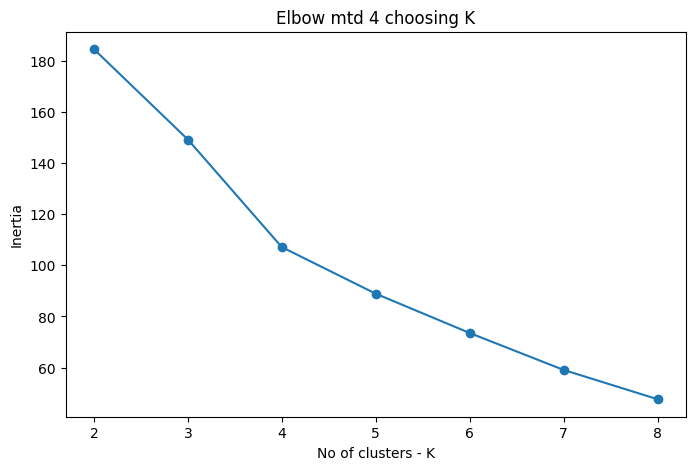

In [144]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.xlabel("No of clusters - K")
plt.ylabel("Inertia")
plt.title("Elbow mtd 4 choosing K")

plt.xticks(list(k_values))
plt.show()

In [145]:
# Final K-Means model - K = 4

kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df_cluster["cluster"] = kmeans_final.fit_predict(X_scaled)

print("Cluster counts:")
print(df_cluster["cluster"].value_counts().sort_index())

cluster_profiles = (
    df_cluster
    .groupby("cluster")[percentage_columns]
    .mean()
)

print("Cluster profiles:")
cluster_profiles

Cluster counts:
cluster
0    12
1    26
2     4
3     8
Name: count, dtype: int64
Cluster profiles:


,food_pct,social_pct,shopping_pct,entertainment_pct,other_splurging_pct
cluster,,,,,
0,50.167484,29.934368,19.564815,0.333333,0.000000
1,33.292874,23.740163,28.783625,13.508574,0.674764
2,12.614040,12.441259,29.995918,1.567069,43.381714
3,28.713206,6.970551,64.316243,0.000000,0.000000


In [146]:
df_cluster[
    ["name"] + percentage_columns + ["cluster"]
].sort_values("cluster")

,name,food_pct,social_pct,shopping_pct,entertainment_pct,other_splurging_pct,cluster
8,Swara Kothari,40.000000,24.000000,32.000000,4.000000,0.000000,0
7,Mihir parmar,50.000000,20.000000,30.000000,0.000000,0.000000,0
15,Gurpreeti Goswami,40.000000,40.000000,20.000000,0.000000,0.000000,0
11,Kavya,50.000000,50.000000,0.000000,0.000000,0.000000,0
17,Vedant,50.000000,25.000000,25.000000,0.000000,0.000000,0
25,leyla,37.500000,25.000000,37.500000,0.000000,0.000000,0
21,Prem Adhiya,60.000000,40.000000,0.000000,0.000000,0.000000,0
18,kunjal,100.000000,0.000000,0.000000,0.000000,0.000000,0
22,Surabhi Prabhu,41.176471,58.823529,0.000000,0.000000,0.000000,0
27,Aarav,37.500000,25.000000,37.500000,0.000000,0.000000,0


In [147]:
cluster_profiles.round(2)

,food_pct,social_pct,shopping_pct,entertainment_pct,other_splurging_pct
cluster,,,,,
0,50.17,29.93,19.56,0.33,0.00
1,33.29,23.74,28.78,13.51,0.67
2,12.61,12.44,30.00,1.57,43.38
3,28.71,6.97,64.32,0.00,0.00


In [148]:
cluster_names = {
    0: "Food + Social",
    1: "Balanced",
    2: "Other-Splurging Heavy",
    3: "Shopping Heavy"
}

In [149]:
profile_allocations = cluster_profiles.copy()

profile_allocations.columns = [
    "Food",
    "Social",
    "Shopping",
    "Entertainment",
    "Other"
]

profile_allocations = profile_allocations.round(2)

profile_allocations

,Food,Social,Shopping,Entertainment,Other
cluster,,,,,
0,50.17,29.93,19.56,0.33,0.00
1,33.29,23.74,28.78,13.51,0.67
2,12.61,12.44,30.00,1.57,43.38
3,28.71,6.97,64.32,0.00,0.00


In [150]:
def allocate_discretionary_budget(discretionary_budget, cluster):
    profile = profile_allocations.loc[cluster]

    allocation = (profile / 100) * discretionary_budget

    return allocation.round(2)

In [151]:
allocate_discretionary_budget(5000, 3)

,3
Food,1435.5
Social,348.5
Shopping,3216.0
Entertainment,0.0
Other,0.0


for enteries

In [152]:
def predict_student_cluster(food, social, shopping, entertainment, other):

    total = food + social + shopping + entertainment + other

    if total == 0:
        return None

    spending_percentages = [[
        (food / total) * 100,
        (social / total) * 100,
        (shopping / total) * 100,
        (entertainment / total) * 100,
        (other / total) * 100
    ]]

    spending_df = pd.DataFrame(
        spending_percentages,
        columns=percentage_columns
    )

    spending_scaled = scaler.transform(spending_df)

    cluster = kmeans_final.predict(spending_scaled)[0]

    return cluster

In [153]:
test_cluster = predict_student_cluster(
    food=3000,
    social=1500,
    shopping=500,
    entertainment=0,
    other=0
)

print("Cluster:", test_cluster)
print("Profile:", cluster_names[test_cluster])

Cluster: 0
Profile: Food + Social


In [154]:
def calculate_monthly_budget(total_money, necessary_expenses):

    money_after_expenses = total_money - necessary_expenses

    if money_after_expenses <= 0:
        return {
            "money_after_expenses": money_after_expenses,
            "savings": 0,
            "discretionary_budget": 0
        }

    if money_after_expenses <= 1000:
        savings_rate = 0.07

    elif money_after_expenses <= 2500:
        savings_rate = 0.10

    elif money_after_expenses <= 5000:
        savings_rate = 0.15

    elif money_after_expenses <= 10000:
        savings_rate = 0.20

    elif money_after_expenses <= 20000:
        savings_rate = 0.25

    elif money_after_expenses <= 30000:
        savings_rate = 0.30

    else:
        savings_rate = 0.35

    savings = money_after_expenses * savings_rate

    discretionary_budget = money_after_expenses - savings

    return {
        "money_after_expenses": round(money_after_expenses, 2),
        "savings": round(savings, 2),
        "discretionary_budget": round(discretionary_budget, 2)
    }

In [155]:
monthly_budget = calculate_monthly_budget(
    total_money=15000,
    necessary_expenses=5000
)

print(monthly_budget)

{'money_after_expenses': 10000, 'savings': 2000.0, 'discretionary_budget': 8000.0}


connecting

In [156]:
final_allocation = allocate_discretionary_budget(
    monthly_budget["discretionary_budget"],
    test_cluster
)

print(final_allocation)

Food             4013.6
Social           2394.4
Shopping         1564.8
Entertainment      26.4
Other               0.0
Name: 0, dtype: float64


In [157]:
def generate_budget(
    food,
    social,
    shopping,
    entertainment,
    other,
    total_money,
    necessary_expenses
):

    # 1. Find the student's spending profile
    cluster = predict_student_cluster(
        food,
        social,
        shopping,
        entertainment,
        other
    )

    # 2. Calculate this month's savings and discretionary budget
    monthly_budget = calculate_monthly_budget(
        total_money,
        necessary_expenses
    )

    # 3. Allocate discretionary money according to the profile
    allocation = allocate_discretionary_budget(
        monthly_budget["discretionary_budget"],
        cluster
    )

    return {
        "cluster": cluster,
        "profile": cluster_names[cluster],
        "money_after_expenses": monthly_budget["money_after_expenses"],
        "savings": monthly_budget["savings"],
        "discretionary_budget": monthly_budget["discretionary_budget"],
        "allocation": allocation
    }

In [158]:
result = generate_budget(
    food=3000,
    social=1500,
    shopping=500,
    entertainment=0,
    other=0,
    total_money=15000,
    necessary_expenses=5000
)

print("Cluster:", result["cluster"])
print("Profile:", result["profile"])
print("Money after necessary expenses:", result["money_after_expenses"])
print("Recommended savings:", result["savings"])
print("Discretionary budget:", result["discretionary_budget"])

print("\nPersonalized spending allocation:")
print(result["allocation"])

Cluster: 0
Profile: Food + Social
Money after necessary expenses: 10000
Recommended savings: 2000.0
Discretionary budget: 8000.0

Personalized spending allocation:
Food             4013.6
Social           2394.4
Shopping         1564.8
Entertainment      26.4
Other               0.0
Name: 0, dtype: float64


In [159]:
print("\nPersonalized spending allocation:")

for category, amount in result["allocation"].items():
    print(f"{category}: ₹{amount:,.0f}")


Personalized spending allocation:
Food: ₹4,014
Social: ₹2,394
Shopping: ₹1,565
Entertainment: ₹26
Other: ₹0


GUI

In [160]:
!pip install -q gradio plotly

import gradio as gr
import plotly.express as px
import pandas as pd

In [161]:
def identify_spending_profile(food, social, shopping, entertainment, other):

    food = food or 0
    social = social or 0
    shopping = shopping or 0
    entertainment = entertainment or 0
    other = other or 0

    total = food + social + shopping + entertainment + other

    if total <= 0:
        return (
            "### ⚠️ Please enter some spending first.",
            None,
            gr.update(visible=False)
        )

    cluster = predict_student_cluster(
        food,
        social,
        shopping,
        entertainment,
        other
    )

    profile = cluster_names[cluster]

    profile_messages = {
        "Food + Social":
            "**Foodie, huh?**\n\n"
            "A bigger part of your spending usually goes toward food and social activities.",

        "Balanced":
            "**Good job, dude. You are a balanced spender.**\n\n"
            "Your spending is spread fairly across different categories.",

        "Other-Splurging Heavy":
            "**Oh! You spend a lot on other stuff.**\n\n"
            "You have a varied spending pattern, with a larger share going toward other discretionary spending.",

        "Shopping Heavy":
            "**You're a shopaholic.**\n\n"
            "Shopping takes a larger share of your discretionary spending, but I get it."
    }

    message = f"""
# 👀 Here's What We Found

## {profile}

{profile_messages[profile]}

---

### Now let's finally build a budget for you.
"""

    return (
        message,
        cluster,
        gr.update(visible=True)
    )


def show_budget_section():
    return gr.update(visible=True)


def create_final_budget(
    pocket_money,
    work_income,
    additional_income,
    rent,
    loan_emi_sip,
    transport,
    groceries,
    education,
    phone_internet,
    other_necessary,
    cluster
):

    if cluster is None:
        return (
            "### ⚠️ Please complete your spending profile first.",
            None,
            gr.update(visible=False)
        )

    pocket_money = pocket_money or 0
    work_income = work_income or 0
    additional_income = additional_income or 0

    rent = rent or 0
    loan_emi_sip = loan_emi_sip or 0
    transport = transport or 0
    groceries = groceries or 0
    education = education or 0
    phone_internet = phone_internet or 0
    other_necessary = other_necessary or 0

    total_money = (
        pocket_money +
        work_income +
        additional_income
    )

    necessary_expenses = (
        rent +
        loan_emi_sip +
        transport +
        groceries +
        education +
        phone_internet +
        other_necessary
    )

    if total_money <= 0:
        return (
            "### ⚠️ Please enter at least one source of income.",
            None,
            gr.update(visible=False)
        )

    if necessary_expenses > total_money:
        return (
            "### ⚠️ Your necessary expenses are higher than your total money available.\n\n"
            "Please check the amounts you entered.",
            None,
            gr.update(visible=False)
        )

    monthly_budget = calculate_monthly_budget(
        total_money,
        necessary_expenses
    )

    allocation = allocate_discretionary_budget(
        monthly_budget["discretionary_budget"],
        cluster
    )

    profile = cluster_names[cluster]

    chart_data = pd.DataFrame({
        "Category": allocation.index,
        "Amount": allocation.values
    })

    chart = px.pie(
        chart_data,
        names="Category",
        values="Amount",
        hole=0.45,
        title="Your Recommended Spending"
    )

    result = f"""
# 🎉 Your Budget Is Ready

<div class="profile-tag">
🧠 {profile}
</div>

---

<div class="result-grid">

<div class="money-card">
<span>💰 Money Available</span>
<h2>₹{total_money:,.0f}</h2>
</div>

<div class="saving-card">
<span>💚 Recommended Savings</span>
<h2>₹{monthly_budget["savings"]:,.0f}</h2>
</div>

</div>

## 📊 Your Monthly Breakdown

| | Amount |
|---|---:|
| 💰 Money available | ₹{total_money:,.0f} |
| 🏠 Necessary expenses | ₹{necessary_expenses:,.0f} |
| 💵 Money left | ₹{monthly_budget["money_after_expenses"]:,.0f} |
| 💚 Recommended savings | ₹{monthly_budget["savings"]:,.0f} |
| 💳 Discretionary budget | ₹{monthly_budget["discretionary_budget"]:,.0f} |

---

## ✨ How You Can Use Your Discretionary Budget

| Category | Suggested Amount |
|---|---:|
| 🍕 Food | ₹{allocation["Food"]:,.0f} |
| 👥 Social | ₹{allocation["Social"]:,.0f} |
| 🛍️ Shopping | ₹{allocation["Shopping"]:,.0f} |
| 🎧 Entertainment | ₹{allocation["Entertainment"]:,.0f} |
| ✨ Other | ₹{allocation["Other"]:,.0f} |

Your suggestions are based on your usual spending pattern.
"""

    return (
        result,
        chart,
        gr.update(visible=True)
    )

In [162]:
# ==========================================
# KAYbudget GUI
# ==========================================

custom_css = """
body {
    background-color: #DCE8D5 !important;
}

.gradio-container {
    max-width: 1050px !important;
    margin: auto !important;
    background-color: #DCE8D5 !important;
}

h1, h2, h3 {
    color: #14532D !important;
}

.app-title {
    text-align: center;
    padding: 25px 10px 10px 10px;
}

.app-title h1 {
    font-size: 42px !important;
    color: #064E3B !important;
    margin-bottom: 5px;
}

.app-subtitle {
    color: #475569;
    font-size: 17px;
}

.section-card {
    background-color: #F8FAF5;
    border-radius: 20px;
    padding: 25px;
    border: 1px solid #B7CBB0;
    box-shadow: 0 4px 12px rgba(20, 83, 45, 0.08);
    margin-top: 15px;
}

input {
    border-radius: 12px !important;
    border: 1px solid #A8BDA1 !important;
}

input[type="number"]::-webkit-inner-spin-button,
input[type="number"]::-webkit-outer-spin-button {
    -webkit-appearance: none;
    margin: 0;
}

input[type="number"] {
    -moz-appearance: textfield !important;
}

button {
    border-radius: 12px !important;
    font-weight: 600 !important;
}

.primary-btn {
    background-color: #047857 !important;
    color: white !important;
    border: none !important;
}

.primary-btn:hover {
    background-color: #065F46 !important;
}

.profile-card {
    background-color: #F8FAF5;
    border-radius: 20px;
    padding: 25px;
    border-left: 6px solid #D946EF;
}

.profile-tag {
    display: inline-block;
    background-color: #E9D5FF;
    color: #14532D;
    padding: 8px 16px;
    border-radius: 20px;
    font-weight: 600;
}

.money-card,
.saving-card {
    background-color: #F8FAF5;
    border-radius: 18px;
    padding: 22px;
    border: 1px solid #B7CBB0;
}

.money-card h2 {
    color: #047857 !important;
}

.saving-card {
    border-left: 5px solid #D946EF;
}

.saving-card h2 {
    color: #C026D3 !important;
}

table {
    border-radius: 12px !important;
    overflow: hidden;
}

.group-link {
    background: transparent !important;
    border: none !important;
    box-shadow: none !important;
    color: #C026D3 !important;
    font-size: 13px !important;
    font-weight: 600 !important;
}

.group-link:hover {
    background: transparent !important;
    color: #A21CAF !important;
}
"""


# ==========================================
# GROUP ANALYSIS
# ==========================================

def create_group_analysis():

    totals = {
        "Food": df["food_eating_out"].sum(),
        "Social": df["social_activities"].sum(),
        "Shopping": df["shopping"].sum(),
        "Entertainment": df["entertainment_hobbies"].sum(),
        "Other": df["other_splurging_amount"].sum()
    }

    chart_data = pd.DataFrame({
        "Category": list(totals.keys()),
        "Total Spending": list(totals.values())
    })

    chart = px.pie(
        chart_data,
        names="Category",
        values="Total Spending",
        hole=0.45,
        title="Group Spending Distribution"
    )

    return chart, chart_data


# ==========================================
# MAIN APP
# ==========================================

with gr.Blocks(
    title="KAYbudget",
    css=custom_css
) as demo:

    # ==========================================
    # BUDGET PAGE
    # ==========================================

    budget_page = gr.Column(visible=True)

    with budget_page:

        # Small Group Analysis option
        with gr.Row():

            gr.HTML("<div style='flex: 1;'></div>")

            group_analysis_button = gr.Button(
                "Check Group Analysis →",
                variant="secondary",
                elem_classes="group-link"
            )


        # ==========================================
        # WELCOME
        # ==========================================

        gr.HTML("""
        <div class="app-title">
            <h1>🌿 KAYbudget</h1>
            <div class="app-subtitle">
                Let's Make Your Budget
            </div>
        </div>
        """)

        gr.Markdown("""
        <div class="section-card">

        ### 💚 Let's Make Your Budget

        Understand how you usually spend, and then create your
        personalized budget, which ensures that you save something.

        </div>
        """)

        start_button = gr.Button(
            "Go Ahead →",
            variant="primary",
            elem_classes="primary-btn"
        )


        # ==========================================
        # USUAL SPENDING
        # ==========================================

        spending_section = gr.Column(
            visible=False,
            elem_classes="section-card"
        )

        with spending_section:

            gr.Markdown("""
            ## 💸 What's Your Usual Spending?

            What do you typically spend in a month? Or what did you spend last month?

            **Enter an appropriate amount.**
            """)

            with gr.Row():

                with gr.Column():

                    food = gr.Number(
                        label="🍕 Food / Eating Out",
                        value=0,
                        minimum=0
                    )

                    social = gr.Number(
                        label="👥 Social Activities",
                        value=0,
                        minimum=0
                    )

                    shopping = gr.Number(
                        label="🛍️ Shopping",
                        value=0,
                        minimum=0
                    )

                with gr.Column():

                    entertainment = gr.Number(
                        label="🎧 Entertainment & Hobbies",
                        value=0,
                        minimum=0
                    )

                    other = gr.Number(
                        label="✨ Amount for all the other spending that you have",
                        value=0,
                        minimum=0
                    )

            analyze_button = gr.Button(
                "Show Me My Spending Style →",
                variant="primary",
                elem_classes="primary-btn"
            )


        # ==========================================
        # PROFILE
        # ==========================================

        profile_section = gr.Column(
            visible=False,
            elem_classes="profile-card"
        )

        with profile_section:

            profile_result = gr.Markdown()

            build_button = gr.Button(
                "Build My Budget →",
                variant="primary",
                elem_classes="primary-btn"
            )

        cluster_state = gr.State(None)


        # ==========================================
        # BUDGET INPUTS
        # ==========================================

        budget_section = gr.Column(
            visible=False,
            elem_classes="section-card"
        )

        with budget_section:

            gr.Markdown("""
            # 💰 This Month

            ### How much money do you have available?
            """)

            gr.Markdown(
                "Add everything you expect to have available this month."
            )

            gr.Markdown("### 💵 Income")

            with gr.Row():

                pocket_money = gr.Number(
                    label="Pocket Money",
                    value=0,
                    minimum=0
                )

                work_income = gr.Number(
                    label="Work / Part-time Income",
                    value=0,
                    minimum=0
                )

                additional_income = gr.Number(
                    label="Additional Income",
                    value=0,
                    minimum=0
                )

            gr.Markdown("---")

            gr.Markdown("""
            ### 🏠 Necessary Expenses

            Enter ₹0 if something does not apply to you this month.
            """)

            with gr.Row():

                with gr.Column():

                    rent = gr.Number(
                        label="Rent",
                        value=0,
                        minimum=0
                    )

                    loan_emi_sip = gr.Number(
                        label="Loan EMI / SIP",
                        value=0,
                        minimum=0
                    )

                    transport = gr.Number(
                        label="Transport",
                        value=0,
                        minimum=0
                    )

                    groceries = gr.Number(
                        label="Groceries",
                        value=0,
                        minimum=0
                    )

                with gr.Column():

                    education = gr.Number(
                        label="Education / Course Fees",
                        value=0,
                        minimum=0
                    )

                    phone_internet = gr.Number(
                        label="Phone / Internet",
                        value=0,
                        minimum=0
                    )

                    other_necessary = gr.Number(
                        label="Other Necessary Expenses",
                        value=0,
                        minimum=0
                    )

            create_button = gr.Button(
                "Create My Budget ✨",
                variant="primary",
                elem_classes="primary-btn"
            )


        # ==========================================
        # FINAL RESULT
        # ==========================================

        final_section = gr.Column(
            visible=False,
            elem_classes="section-card"
        )

        with final_section:

            final_result = gr.Markdown()

            final_chart = gr.Plot(
                label="Recommended Spending"
            )


    # ==========================================
    # GROUP ANALYSIS PAGE
    # ==========================================

    group_analysis_section = gr.Column(
        visible=False,
        elem_classes="section-card"
    )

    with group_analysis_section:

        gr.Markdown("""
        # 📊 Group Analysis

        Explore how students in the survey usually spend their money.
        """)

        group_chart = gr.Plot(
            value=create_group_analysis()[0],
            label="Group Spending"
        )

        group_table = gr.Dataframe(
            value=create_group_analysis()[1],
            headers=["Category", "Total Spending"],
            interactive=False
        )

        back_button = gr.Button(
            "← Make Your Budget",
            variant="secondary"
        )


    # ==========================================
    # BUTTON CONNECTIONS
    # ==========================================

    start_button.click(
        fn=lambda: gr.update(visible=True),
        inputs=None,
        outputs=spending_section
    )


    analyze_button.click(
        fn=identify_spending_profile,

        inputs=[
            food,
            social,
            shopping,
            entertainment,
            other
        ],

        outputs=[
            profile_result,
            cluster_state,
            profile_section
        ]
    )


    build_button.click(
        fn=show_budget_section,

        inputs=None,

        outputs=budget_section
    )


    create_button.click(
        fn=create_final_budget,

        inputs=[
            pocket_money,
            work_income,
            additional_income,

            rent,
            loan_emi_sip,
            transport,
            groceries,
            education,
            phone_internet,
            other_necessary,

            cluster_state
        ],

        outputs=[
            final_result,
            final_chart,
            final_section
        ]
    )


    # Open Group Analysis
    group_analysis_button.click(
        fn=lambda: [
            gr.update(visible=False),
            gr.update(visible=True)
        ],

        inputs=None,

        outputs=[
            budget_page,
            group_analysis_section
        ]
    )


    # Return to Budget
    back_button.click(
        fn=lambda: [
            gr.update(visible=True),
            gr.update(visible=False)
        ],

        inputs=None,

        outputs=[
            budget_page,
            group_analysis_section
        ]
    )


# ==========================================
# LAUNCH
# ==========================================

demo.launch(share=True)

/tmp/ipykernel_1361/489825393.py:166: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css. Please pass these parameters to launch() instead.



Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4dfda04aa3a37bd9bf.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
